In [1]:
# 1. Imports
import time
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# 2. Load and preprocess CIFAR-10
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
y_train = y_train.flatten()
y_test = y_test.flatten()

class_names = ['airplane','automobile','bird','cat','deer',
               'dog','frog','horse','ship','truck']

print("Train shape:", x_train.shape, "Test shape:", x_test.shape)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2190s 13us/step
Train shape: (50000, 32, 32, 3) Test shape: (10000, 32, 32, 3)


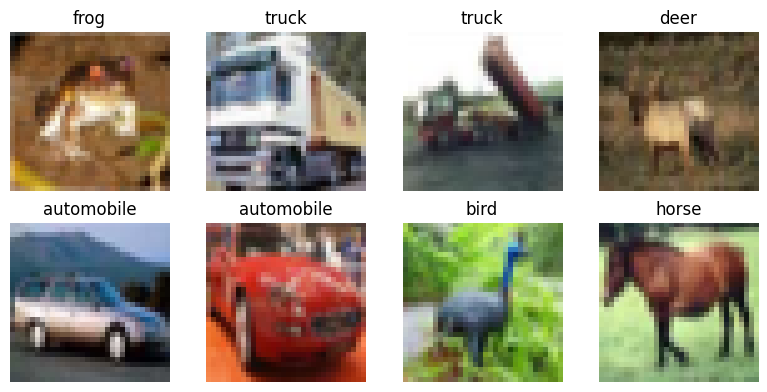

In [3]:
# Quick peek at a few images
plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis('off')
plt.tight_layout()
plt.show()


In [4]:
def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam",
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_cnn().summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 658,218 (2.51 MB)

 Trainable params: 658,218 (2.51 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# train without augmentation
EPOCHS = 20
BATCH_SIZE = 64

model_no_aug = build_cnn()

start = time.time()
history_no_aug = model_no_aug.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2
)
time_no_aug = time.time() - start
print(f"Training time (no augmentation): {time_no_aug:.2f}s")


Epoch 1/20
782/782 - 18s - 23ms/step - accuracy: 0.4012 - loss: 1.6320 - val_accuracy: 0.5363 - val_loss: 1.2731
Epoch 2/20
782/782 - 5s - 6ms/step - accuracy: 0.5583 - loss: 1.2399 - val_accuracy: 0.6184 - val_loss: 1.0879
Epoch 3/20
782/782 - 5s - 6ms/step - accuracy: 0.6214 - loss: 1.0753 - val_accuracy: 0.6756 - val_loss: 0.9152
Epoch 4/20
782/782 - 5s - 6ms/step - accuracy: 0.6598 - loss: 0.9685 - val_accuracy: 0.7053 - val_loss: 0.8379
Epoch 5/20
782/782 - 5s - 6ms/step - accuracy: 0.6899 - loss: 0.8881 - val_accuracy: 0.7193 - val_loss: 0.8139
Epoch 6/20
782/782 - 6s - 8ms/step - accuracy: 0.7089 - loss: 0.8387 - val_accuracy: 0.7342 - val_loss: 0.7626
Epoch 7/20
782/782 - 5s - 6ms/step - accuracy: 0.7221 - loss: 0.7974 - val_accuracy: 0.7490 - val_loss: 0.7160
Epoch 8/20
782/782 - 5s - 6ms/step - accuracy: 0.7316 - loss: 0.7658 - val_accuracy: 0.7459 - val_loss: 0.7302
Epoch 9/20
782/782 - 5s - 6ms/step - accuracy: 0.7403 - loss: 0.7434 - val_accuracy: 0.7603 - val_loss: 0.6880

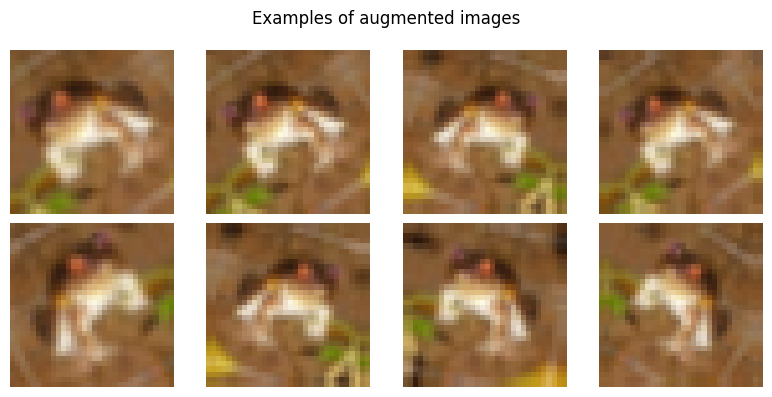

In [6]:
# train with augmentation
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),   # up to ~36 degrees
    layers.RandomZoom(0.1),
])

# Visualize a few augmented samples
plt.figure(figsize=(8, 4))
sample_img = np.expand_dims(x_train[0], 0)
for i in range(8):
    aug_img = data_augmentation(sample_img, training=True)
    plt.subplot(2, 4, i + 1)
    plt.imshow(aug_img[0].numpy())
    plt.axis('off')
plt.suptitle("Examples of augmented images")
plt.tight_layout()
plt.show()


In [7]:
model_aug = build_cnn()

# Wrap the augmentation layers + model together
inputs = keras.Input(shape=(32, 32, 3))
x = data_augmentation(inputs)
outputs = model_aug(x)
aug_pipeline_model = keras.Model(inputs, outputs)
aug_pipeline_model.compile(optimizer="adam",
                            loss="sparse_categorical_crossentropy",
                            metrics=["accuracy"])

start = time.time()
history_aug = aug_pipeline_model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=2
)
time_aug = time.time() - start
print(f"Training time (with augmentation): {time_aug:.2f}s")


Epoch 1/20
782/782 - 14s - 18ms/step - accuracy: 0.3633 - loss: 1.7345 - val_accuracy: 0.4967 - val_loss: 1.4089
Epoch 2/20
782/782 - 9s - 11ms/step - accuracy: 0.4956 - loss: 1.4051 - val_accuracy: 0.5581 - val_loss: 1.2440
Epoch 3/20
782/782 - 8s - 10ms/step - accuracy: 0.5422 - loss: 1.2877 - val_accuracy: 0.5667 - val_loss: 1.2137
Epoch 4/20
782/782 - 9s - 12ms/step - accuracy: 0.5668 - loss: 1.2192 - val_accuracy: 0.6242 - val_loss: 1.0571
Epoch 5/20
782/782 - 9s - 11ms/step - accuracy: 0.5890 - loss: 1.1591 - val_accuracy: 0.6280 - val_loss: 1.0587
Epoch 6/20
782/782 - 8s - 10ms/step - accuracy: 0.6053 - loss: 1.1240 - val_accuracy: 0.6771 - val_loss: 0.9117
Epoch 7/20
782/782 - 8s - 11ms/step - accuracy: 0.6166 - loss: 1.0921 - val_accuracy: 0.6423 - val_loss: 1.0188
Epoch 8/20
782/782 - 8s - 11ms/step - accuracy: 0.6277 - loss: 1.0582 - val_accuracy: 0.6446 - val_loss: 1.0300
Epoch 9/20
782/782 - 8s - 11ms/step - accuracy: 0.6332 - loss: 1.0457 - val_accuracy: 0.6812 - val_loss

In [8]:
loss_no_aug, acc_no_aug = model_no_aug.evaluate(x_test, y_test, verbose=0)
loss_aug, acc_aug = aug_pipeline_model.evaluate(x_test, y_test, verbose=0)

print(f"{'Setup':<20}{'Test Accuracy':<18}{'Test Loss':<15}{'Time (s)'}")
print(f"{'No Augmentation':<20}{acc_no_aug:<18.4f}{loss_no_aug:<15.4f}{time_no_aug:.2f}")
print(f"{'With Augmentation':<20}{acc_aug:<18.4f}{loss_aug:<15.4f}{time_aug:.2f}")


Setup               Test Accuracy     Test Loss      Time (s)
No Augmentation     0.7851            0.6388         111.85
With Augmentation   0.7237            0.7999         174.73


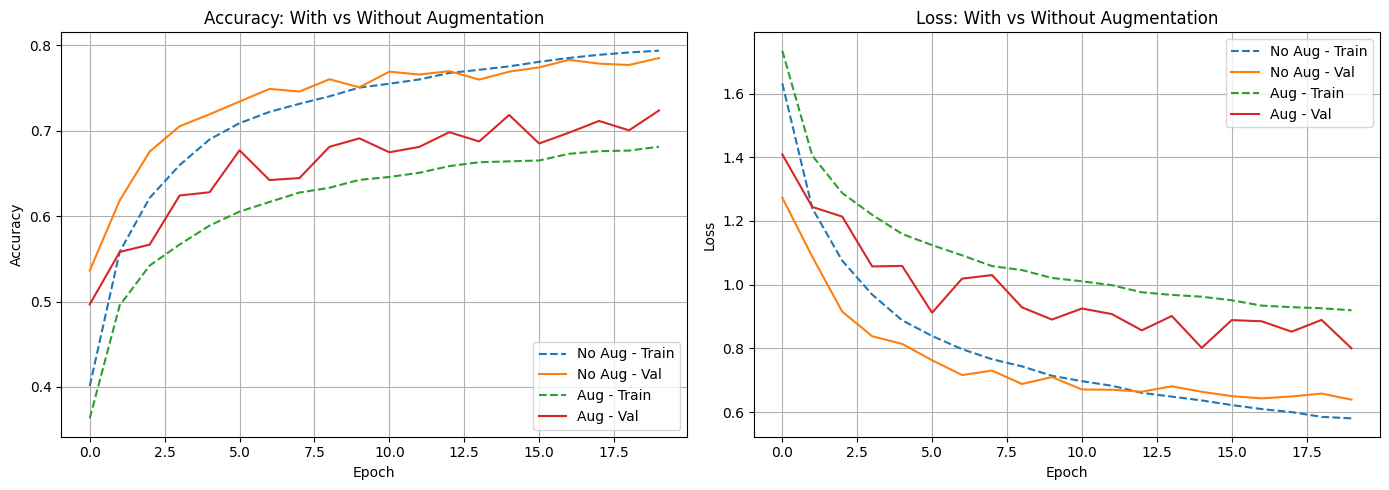

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy: train vs val, for both setups
axes[0].plot(history_no_aug.history['accuracy'], '--', label='No Aug - Train')
axes[0].plot(history_no_aug.history['val_accuracy'], label='No Aug - Val')
axes[0].plot(history_aug.history['accuracy'], '--', label='Aug - Train')
axes[0].plot(history_aug.history['val_accuracy'], label='Aug - Val')
axes[0].set_title('Accuracy: With vs Without Augmentation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True)

# Loss: train vs val, for both setups
axes[1].plot(history_no_aug.history['loss'], '--', label='No Aug - Train')
axes[1].plot(history_no_aug.history['val_loss'], label='No Aug - Val')
axes[1].plot(history_aug.history['loss'], '--', label='Aug - Train')
axes[1].plot(history_aug.history['val_loss'], label='Aug - Val')
axes[1].set_title('Loss: With vs Without Augmentation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [10]:
gap_no_aug = history_no_aug.history['accuracy'][-1] - history_no_aug.history['val_accuracy'][-1]
gap_aug = history_aug.history['accuracy'][-1] - history_aug.history['val_accuracy'][-1]

print(f"""
ANALYSIS: Effect of Data Augmentation
------------------------------------------------
Final Train-Val Accuracy Gap (No Augmentation): {gap_no_aug:.4f}
Final Train-Val Accuracy Gap (With Augmentation): {gap_aug:.4f}

Test Accuracy -> No Aug: {acc_no_aug:.4f} | With Aug: {acc_aug:.4f}

A smaller train-val gap with augmentation indicates the model overfits less
and generalizes better to unseen data, because random flips/rotations/zooms
act as a form of regularization, exposing the model to more visual
variation without needing more labeled data.
""")



ANALYSIS: Effect of Data Augmentation
------------------------------------------------
Final Train-Val Accuracy Gap (No Augmentation): 0.0086
Final Train-Val Accuracy Gap (With Augmentation): -0.0424

Test Accuracy -> No Aug: 0.7851 | With Aug: 0.7237

A smaller train-val gap with augmentation indicates the model overfits less
and generalizes better to unseen data, because random flips/rotations/zooms
act as a form of regularization, exposing the model to more visual
variation without needing more labeled data.

